In [205]:
import pandas as pd 
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression # build our model
from sklearn.metrics import mean_absolute_error #evaluate our model
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error #evaluate
import warnings
warnings.simplefilter(action='ignore')

In [246]:
df = pd.read_csv(r"C:\Users\USER\Downloads\python-for-data-science-course-main\white wine quality.csv",sep=';')
df.head(10)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
5,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
6,6.2,0.32,0.16,7.0,0.045,30.0,136.0,0.9949,3.18,0.47,9.6,6
7,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
8,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
9,8.1,0.22,0.43,1.5,0.044,28.0,129.0,0.9938,3.22,0.45,11.0,6


In [247]:
df.info()
df.shape

<class 'pandas.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB


(4898, 12)

In [248]:
df.columns = df.columns.str.strip()

In [209]:
df['citric acid'].unique()

array([0.36, 0.34, 0.4 , 0.32, 0.16, 0.43, 0.41, 0.37, 0.62, 0.38, 0.04,
       0.48, 0.42, 0.14, 0.35, 0.39, 0.2 , 0.23, 0.26, 0.27, 0.31, 0.25,
       0.29, 0.33, 0.59, 0.15, 0.24, 0.07, 0.03, 0.13, 0.28, 0.46, 0.3 ,
       0.61, 0.63, 0.66, 0.54, 0.5 , 0.  , 0.47, 0.56, 0.22, 0.67, 0.18,
       0.45, 0.44, 0.88, 0.21, 0.08, 0.49, 0.58, 0.7 , 0.6 , 0.51, 0.1 ,
       0.19, 0.12, 0.09, 0.53, 0.02, 0.65, 0.17, 0.71, 0.06, 0.68, 0.72,
       0.69, 1.66, 0.57, 0.05, 0.52, 1.  , 0.01, 0.74, 0.81, 0.55, 0.64,
       0.73, 0.99, 0.78, 0.79, 0.82, 0.8 , 1.23, 0.86, 0.11, 0.91])

In [249]:
df.shape

(4898, 12)

In [211]:
df.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='str')

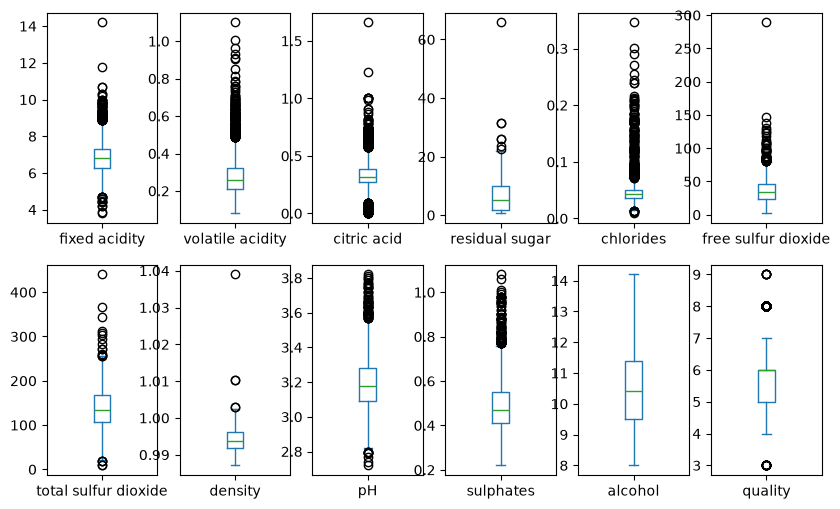

In [212]:
var = ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality']
df.var = df.apply(lambda x: x.str.strip() if x.dtype=='object' else x)
df[var].plot(
    figsize=(10,6),
    kind= 'box',
    subplots = True,
    layout = (2,6)
);

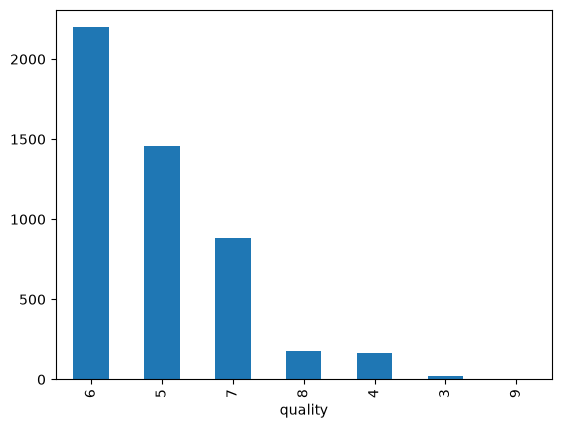

In [213]:
df['quality'].value_counts().plot(kind='bar');

In [214]:
df['quality'].nunique()

7

In [215]:
x = df.drop('quality', axis=1)
x.info()

<class 'pandas.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
dtypes: float64(11)
memory usage: 421.1 KB


In [216]:
y = df['quality'].apply(lambda x: 1 if x > 6 else 0)
y.head(20)

0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    1
14    0
15    1
16    0
17    1
18    0
19    0
Name: quality, dtype: int64

<Axes: xlabel='quality'>

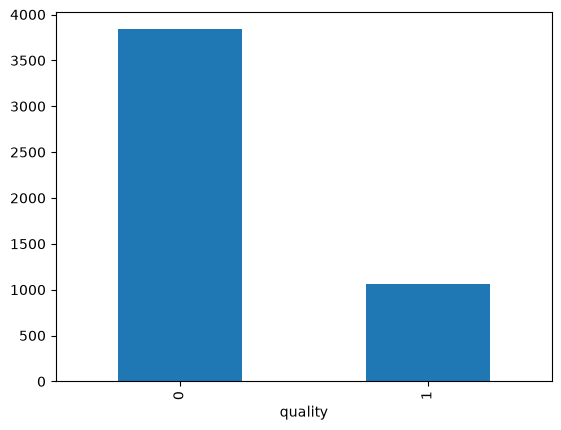

In [217]:
y.value_counts().plot(kind='bar')

<Axes: xlabel='quality'>

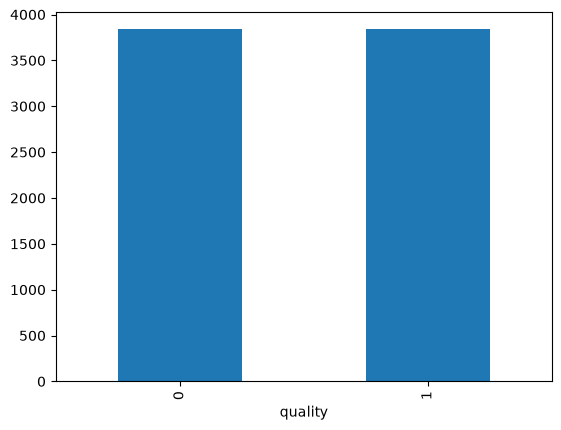

In [218]:
yy = SMOTE(sampling_strategy = 'auto', random_state = 42)
x_res,y_res = yy.fit_resample(x,y)

y_res.value_counts().plot(kind='bar')

In [219]:
x_train,x_test,y_train,y_test = train_test_split(x_res,y_res,
                                                test_size=0.2,
                                                random_state=42)

print(x_train.shape)
print(x_res.shape)

(6140, 11)
(7676, 11)


In [267]:
rmc = RandomForestClassifier()

In [268]:
rmc.fit(x_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [269]:
y_pred = rmc.predict(x_test)
print(y_pred)

[1 1 1 ... 1 0 1]


In [270]:
accuracy = accuracy_score(y_test,y_pred)
recall = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)
precision = precision_score(y_test,y_pred)
print('accuracy: {:.2f} '.format(accuracy))
print('recall: {:.2f}'.format(recall))
print('f1: {:.2f}'.format(f1))
print('precision: {:.2f}'.format(precision))

accuracy: 0.91 
recall: 0.93
f1: 0.91
precision: 0.90


## logistic regression

In [271]:
lr = LogisticRegression()

In [272]:
lr.fit(x_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [273]:
lr_pred = lr.predict(x_test)
print(lr_pred)

[0 0 1 ... 1 0 1]


In [274]:
accuracy = accuracy_score(y_test,lr_pred)
recall = recall_score(y_test,lr_pred)
f1 = f1_score(y_test,lr_pred)
precision = precision_score(y_test,lr_pred)
print('accuracy: {:.2f} '.format(accuracy))
print('recall: {:.2f}'.format(recall))
print('f1: {:.2f}'.format(f1))
print('precision: {:.2f}'.format(precision))

accuracy: 0.73 
recall: 0.73
f1: 0.73
precision: 0.73


In [275]:
svc=SVC()

In [276]:
svc.fit(x_train,y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [277]:
svc_pred = svc.predict(x_test)
print(svc_pred)

[0 1 1 ... 1 0 1]


In [278]:
accuracy = accuracy_score(y_test,svc_pred)
recall = recall_score(y_test,svc_pred)
f1 = f1_score(y_test,svc_pred)
precision = precision_score(y_test,svc_pred)
print('accuracy: {:.2f} '.format(accuracy))
print('recall: {:.2f}'.format(recall))
print('f1: {:.2f}'.format(f1))
print('precision: {:.2f}'.format(precision))

accuracy: 0.69 
recall: 0.74
f1: 0.71
precision: 0.68


## using linearRegression

In [279]:
df.shape

(4898, 12)

In [280]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


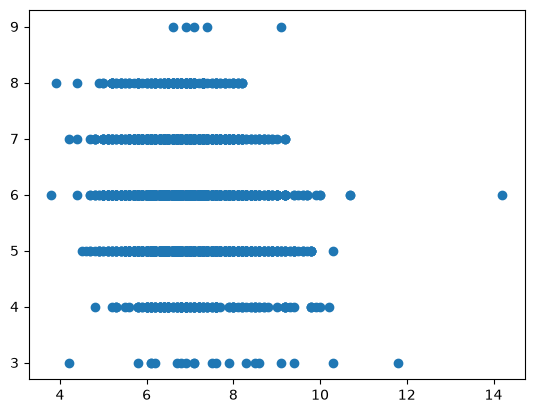

In [281]:
a = df['fixed acidity']
b = df['quality']

plt.scatter(a,b)
figsize=(20,4)

In [282]:
a = df[['fixed acidity']]
b = df['quality']

In [283]:
a_train,a_test,b_train,b_test = train_test_split(a,b,
                                                test_size=0.2,
                                                random_state=42)

In [284]:
print(type(a_train))
print(type(b_train))

<class 'pandas.DataFrame'>
<class 'pandas.Series'>


In [285]:
mdr =LinearRegression()

In [286]:
mdr.fit(a_train,b_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[-0.12]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['fixed acidity']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,6.722
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [287]:
b_pred = mdr.predict(a_test)
print(b_pred)

[5.97856154 6.052915   5.84224686 5.81746238 5.91660032 5.94138481
 5.85463911 5.78028565 5.69353994 5.64397097 5.92899256 5.89181583
 5.94138481 5.78028565 5.99095378 5.92899256 6.07769948 6.04052275
 5.7678934  5.89181583 5.99095378 5.80507013 5.86703135 5.78028565
 5.99095378 5.78028565 5.87942359 6.09009172 5.64397097 5.71832443
 5.87942359 5.80507013 5.84224686 5.82985462 5.80507013 5.96616929
 5.84224686 5.90420808 5.78028565 5.97856154 5.97856154 5.86703135
 5.86703135 6.07769948 5.94138481 5.85463911 5.85463911 5.99095378
 5.92899256 5.80507013 5.82985462 5.74310892 5.97856154 5.86703135
 5.79267789 5.75550116 5.92899256 5.96616929 5.85463911 5.82985462
 5.74310892 5.95377705 5.94138481 5.96616929 5.89181583 5.81746238
 5.97856154 5.69353994 5.82985462 5.78028565 5.69353994 5.95377705
 5.84224686 5.78028565 5.7678934  5.86703135 5.78028565 5.90420808
 6.10248397 5.80507013 5.84224686 5.95377705 5.86703135 5.74310892
 5.85463911 5.7678934  5.92899256 5.94138481 5.96616929 5.7926

In [288]:
mae = mean_absolute_error(b_pred,b_test)
mse = mean_squared_error(b_pred,b_test)

In [289]:
print('mean absolute error is', mae)
print('mean squared error is', mse)

mean absolute error is 0.6697717020953451
mean squared error is 0.768682864403087


## Polynomial regression

In [290]:
r = df[['fixed acidity']]
z = df['quality']

r_train,r_test,z_train,z_test = train_test_split(r,z,
                                                test_size=0.2,
                                                random_state=42)

In [291]:
poly = PolynomialFeatures(degree=2)
r_train_p = poly.fit_transform(r_train)
r_test_p = poly.fit_transform(r_test)


In [292]:
poly_model = LinearRegression()

In [293]:
poly_model.fit(r_train_p,z_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 0. , 0.44,-0.04]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.748
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[757.24, 5.3 , 0. ]"


In [294]:
z_pred = poly_model.predict(r_test_p)
print(z_pred)

[5.96034603 5.96759549 5.87289828 5.84668807 5.93249391 5.94601413
 5.88481369 5.80142434 5.66804962 5.57438677 5.93965058 5.91580119
 5.94601413 5.80142434 5.96353708 5.93965058 5.96366698 5.96837006
 5.78475018 5.91580119 5.96353708 5.83239328 5.89593598 5.80142434
 5.96353708 5.80142434 5.90626515 5.96051304 5.57438677 5.7101223
 5.90626515 5.83239328 5.87289828 5.86018974 5.83239328 5.95636186
 5.87289828 5.92454411 5.80142434 5.96034603 5.96034603 5.89593598
 5.89593598 5.96366698 5.94601413 5.88481369 5.88481369 5.96353708
 5.93965058 5.83239328 5.86018974 5.74902249 5.96034603 5.89593598
 5.81730537 5.7672829  5.93965058 5.95636186 5.88481369 5.86018974
 5.74902249 5.95158456 5.94601413 5.95636186 5.91580119 5.84668807
 5.96034603 5.66804962 5.86018974 5.80142434 5.66804962 5.95158456
 5.87289828 5.80142434 5.78475018 5.89593598 5.80142434 5.92454411
 5.95656598 5.83239328 5.87289828 5.95158456 5.89593598 5.74902249
 5.88481369 5.78475018 5.93965058 5.94601413 5.95636186 5.81730

In [295]:
mse= mean_squared_error(z_pred,z_test)
mae = mean_absolute_error(z_pred,z_test)
print('mean absolute error is',mae)
print('mean squared reeor is', mse)

mean absolute error is 0.6674361571260167
mean squared reeor is 0.7761387300139319


In [298]:
compare = pd.DataFrame(
    {
        'Modeles':[
            'Random Forest Classifier',
            'Logistics Regression',
            'Support Vector Classifier',
        ],
        'Accuracy':[
            accuracy_score(y_test,y_pred),
            accuracy_score(y_test,lr_pred),
            accuracy_score(y_test,svc_pred),
        ],
        'Precision':[
            precision_score(y_test,y_pred),
            precision_score(y_test,lr_pred),
            precision_score(y_test,svc_pred),
        ],
        'Recall':[
            recall_score(y_test,y_pred),
            recall_score(y_test,lr_pred),
            recall_score(y_test,svc_pred),
        ],
        'F1':[
            f1_score(y_test,y_pred),
            f1_score(y_test,lr_pred),
            f1_score(y_test,svc_pred),
        ]
      
    }
)

In [299]:
compare

,Modeles,Accuracy,Precision,Recall,F1
0,Random Forest Classifier,0.911458,0.897114,0.929779,0.913155
1,Logistics Regression,0.730469,0.730819,0.730819,0.730819
2,Support Vector Classifier,0.692708,0.676157,0.741222,0.707196
